# Task 3: Trò Chơi Kakuro — Thực Nghiệm Bài Toán Thỏa Mãn Ràng Buộc (CSP)
Notebook này kiểm chứng tính đúng đắn (100% thỏa mãn ràng buộc AllDiff và Exact Sum), độ ổn định và hiệu quả tìm kiếm trên 4 bảng câu đố Kakuro (bao gồm bảng mẫu 5x5 và bảng phức tạp 9x9 trong đề bài) với 3 cấu hình bộ giải:
1. Baseline Backtracking (Quay lui cơ bản)
2. Backtracking + Forward Checking (Quay lui kết hợp kiểm tra tiến trên tổ hợp tổng)
3. BT + Extended AC-3 + MRV/Degree/LCV (Tiền xử lý Sum Partitions + Lan truyền cung mở rộng + Bộ ba Heuristic Lecture 08)

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SOURCE_DIR = Path.cwd().parent
if str(SOURCE_DIR) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIR))

from task3 import KakuroCSP, KakuroSolver, SolverMode, SumPartitionCatalog

MAPS_DIR = Path.cwd() / 'maps'
FIG_DIR = SOURCE_DIR.parent / 'report' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams['figure.dpi'] = 130
print("Environment ready.")


Environment ready.


## 1. Đánh Giá Tính Đúng Đắn, Độ Ổn Định Và Hiệu Năng Trên Các Bảng Kakuro

In [2]:
board_files = [
    'board_5x5_example.json',
    'board_6x6_medium.json',
    'board_8x8_hard.json',
    'board_9x9_complex.json',
]
csp_rows = []
solved_9x9 = None
csp_9x9 = None

for fname in board_files:
    csp = KakuroCSP.from_json(MAPS_DIR / fname)
    for mode in [SolverMode.PLAIN_BT, SolverMode.BT_FC, SolverMode.BT_MAC_HEURISTICS]:
        res = KakuroSolver(mode=mode).solve(csp)
        assert res.solved and res.valid_verified
        if fname == 'board_9x9_complex.json' and mode == SolverMode.BT_MAC_HEURISTICS:
            solved_9x9 = res.assignment
            csp_9x9 = csp
        csp_rows.append({
            'Board': csp.name,
            'Variables |X|': len(csp.variables),
            'Runs |C|': len(csp.runs),
            'Solver Configuration': mode.value,
            'Nodes Explored': res.nodes_explored,
            'Backtracks': res.backtracks,
            'Pruned Values': res.pruned_values,
            'Solve Time (ms)': round(res.elapsed_ms, 2),
            'Verified': res.valid_verified,
        })

df_csp = pd.DataFrame(csp_rows)
df_csp

,Board,Variables |X|,Runs |C|,Solver Configuration,Nodes Explored,Backtracks,Pruned Values,Solve Time (ms),Verified
0,Example Board (5x5 - Spec Page 4),12,8,Baseline Backtracking,9933,1097,0,76.93,True
1,Example Board (5x5 - Spec Page 4),12,8,Backtracking + Forward Checking,13,1,97,1.18,True
2,Example Board (5x5 - Spec Page 4),12,8,BT + Extended AC-3 + MRV/Degree/LCV,12,0,96,1.58,True
3,Medium Benchmark Board (6x6),19,12,Baseline Backtracking,6145,671,0,55.00,True
4,Medium Benchmark Board (6x6),19,12,Backtracking + Forward Checking,19,0,138,1.14,True
5,Medium Benchmark Board (6x6),19,12,BT + Extended AC-3 + MRV/Degree/LCV,19,0,136,26.41,True
6,Hard Benchmark Board (8x8),41,22,Baseline Backtracking,8645,933,0,91.63,True
7,Hard Benchmark Board (8x8),41,22,Backtracking + Forward Checking,63,22,410,4.65,True
8,Hard Benchmark Board (8x8),41,22,BT + Extended AC-3 + MRV/Degree/LCV,41,0,320,33.69,True
9,Complex Test Board (9x9 - Spec Page 5),48,28,Baseline Backtracking,9141,988,0,111.26,True


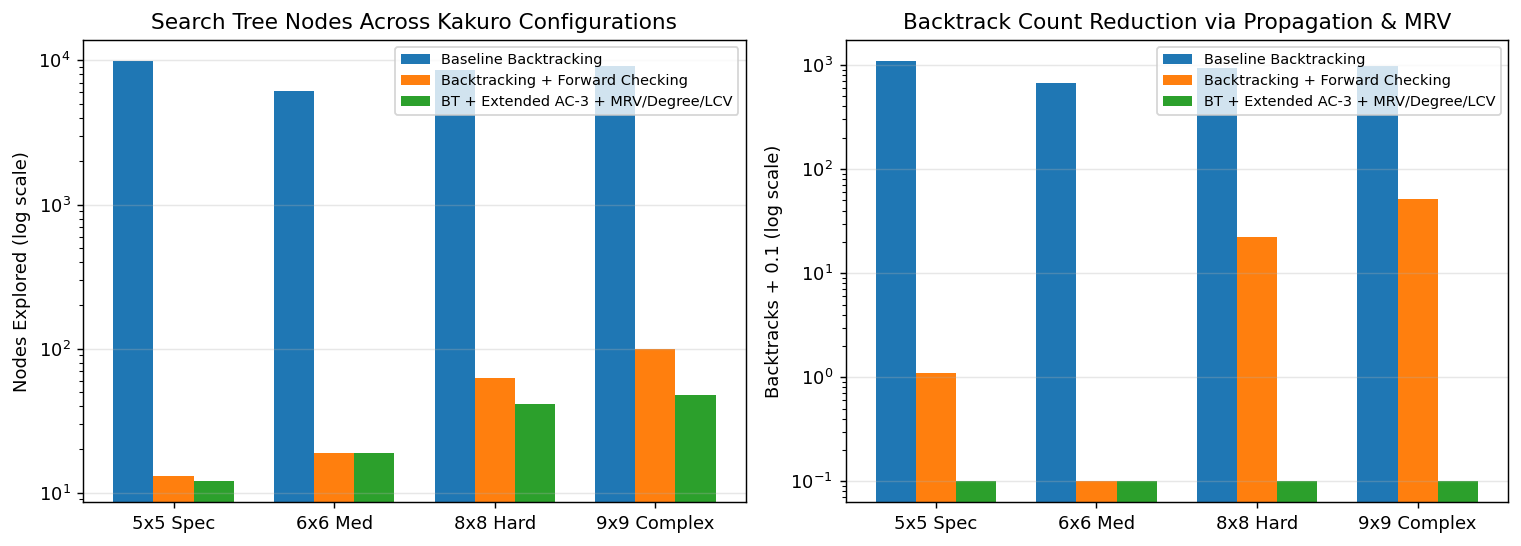

In [3]:
boards_short = ['5x5 Spec', '6x6 Med', '8x8 Hard', '9x9 Complex']
modes = [m.value for m in [SolverMode.PLAIN_BT, SolverMode.BT_FC, SolverMode.BT_MAC_HEURISTICS]]
x = np.arange(len(boards_short))
width = 0.25

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.3))
for idx, m_label in enumerate(modes):
    sub = df_csp[df_csp['Solver Configuration'] == m_label]
    axes[0].bar(x + (idx - 1) * width, sub['Nodes Explored'], width, label=m_label)
    axes[1].bar(x + (idx - 1) * width, sub['Backtracks'] + 0.1, width, label=m_label)

axes[0].set_yscale('log')
axes[0].set_xticks(x)
axes[0].set_xticklabels(boards_short)
axes[0].set_ylabel('Nodes Explored (log scale)')
axes[0].set_title('Search Tree Nodes Across Kakuro Configurations')
axes[0].legend(fontsize=8)
axes[0].grid(True, axis='y', alpha=0.3)

axes[1].set_yscale('log')
axes[1].set_xticks(x)
axes[1].set_xticklabels(boards_short)
axes[1].set_ylabel('Backtracks + 0.1 (log scale)')
axes[1].set_title('Backtrack Count Reduction via Propagation & MRV')
axes[1].legend(fontsize=8)
axes[1].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'task3_csp_benchmark.png', dpi=200)
plt.show()

## 2. Nghiệm Chi Tiết Đã Kiểm Chứng Của Bảng Kiểm Thử Phức Tạp 9x9 (Yêu Cầu 3.2)

In [4]:
grid_display = []
for r in range(csp_9x9.rows):
    row_items = []
    for c in range(csp_9x9.cols):
        spec = csp_9x9.raw_grid[r][c]
        if spec == 'B':
            row_items.append(' ### ')
        elif isinstance(spec, dict):
            d_val = str(spec.get('down', ''))
            a_val = str(spec.get('across', ''))
            row_items.append(f'{d_val:>2}\\{a_val:<2}')
        else:
            row_items.append(f'  {solved_9x9[(r, c)]}  ')
    grid_display.append(' | '.join(row_items))

print('Verified 9x9 Kakuro Solution (All 28 AllDiff & Sum constraints satisfied):')
print('\n'.join(grid_display))

Verified 9x9 Kakuro Solution (All 28 AllDiff & Sum constraints satisfied):
 ###  |  ###  | 44\   | 16\   |  9\   |  ###  | 15\   | 44\   |  ### 
 ###  |   \22 |   5   |   9   |   8   | 11\3  |   1   |   2   | 14\  
 ###  | 17\28 |   2   |   7   |   1   |   3   |   4   |   6   |   5  
  \14 |   8   |   6   |  ###  | 12\20 |   1   |   2   |   8   |   9  
  \17 |   9   |   8   | 29\22 |   3   |   2   |   8   |   9   |  7\  
 ###  | 12\28 |   9   |   8   |   6   |   5   |   \12 |   7   |   5  
  \14 |   3   |   4   |   5   |   2   |  7\   | 12\6  |   4   |   2  
  \39 |   9   |   3   |   7   |   1   |   6   |   8   |   5   |  ### 
 ###  |   \16 |   7   |   9   |   \8  |   1   |   4   |   3   |  ### 
